# **CS 5361/6361 Machine Learning**

**Random forests**

**Classifying MNIST and Predicting the running times of GPU operations under various parameter settings using ensembles of decision trees**

**Author:** [Olac Fuentes](http://www.cs.utep.edu/ofuentes/)<br>
**Last modified:** 3/30/2026<br>

# **Decision Forests**

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import time
from sklearn.metrics import accuracy_score, confusion_matrix,mean_squared_error,mean_absolute_error
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier, HistGradientBoostingClassifier
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor
from sklearn.model_selection import train_test_split
from sklearn import tree
from google.colab import files
import tensorflow as tf

In [ ]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()
x_train = np.float32(x_train/255).reshape(x_train.shape[0],-1)
x_test = np.float32(x_test/255).reshape(x_test.shape[0],-1)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
print(x_train.shape)
print(x_test.shape)

(60000, 784)
(10000, 784)


Recall that we can use decision trees to classify MNIST

In [ ]:
model = DecisionTreeClassifier(criterion='entropy')
model = model.fit(x_train, y_train)
pred = model.predict(x_test)
accuracy = accuracy_score(y_test, pred)
print(f'Accuracy {accuracy:.4}')

Accuracy 0.8837


In [ ]:
start_time = time.time()
model = DecisionTreeClassifier(criterion='entropy')
model = model.fit(x_train, y_train)
end_time = time.time()
training_time = end_time - start_time
print(f'Training time: {training_time:.4f} seconds')

start_time = time.time()
pred = model.predict(x_test)
end_time = time.time()
prediction_time = end_time - start_time
print(f'Prediction time: {prediction_time:.4f} seconds')

accuracy = accuracy_score(y_test, pred)
print(f'Accuracy {accuracy:.4}')

Training time: 22.4722 seconds
Prediction time: 0.0078 seconds
Accuracy 0.8882


We can also see how important each feature is in terms of decreasing entropy or mean-squared error.

In [ ]:
model.feature_importances_

array([0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
      

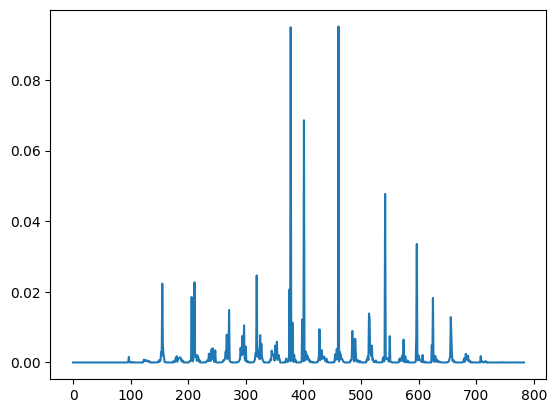

In [ ]:
plt.plot(model.feature_importances_)

It's easier to visialize the importances if we convert them back to a 28-by-28 image.

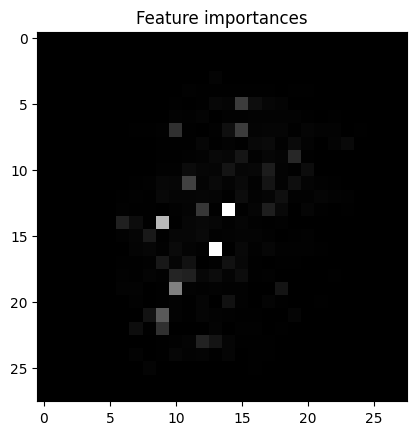

In [ ]:
plt.imshow(model.feature_importances_.reshape(28,28),cmap='gray')
plt.title("Feature importances")
plt.show()

If we replace the default splitter ("best") by "random", we obtain different decision trees every time we train the model.

Despite the fact that the splits aren't the best possible, the resulting accuracy is almost the same and the running time decreses.


Training time: 5.7567 seconds
Prediction time: 0.0080 seconds
Accuracy 0.8855


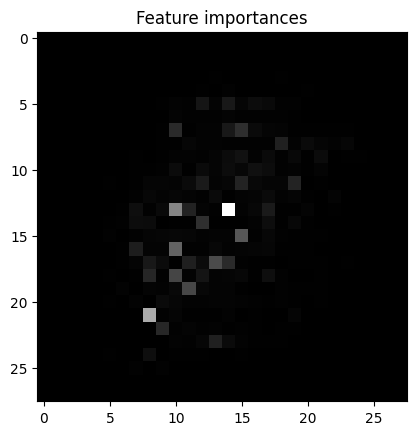

In [ ]:
start_time = time.time()
model = DecisionTreeClassifier(criterion='entropy', splitter='random')
model = model.fit(x_train, y_train)
end_time = time.time()
training_time = end_time - start_time
print(f'Training time: {training_time:.4f} seconds')

start_time = time.time()
pred = model.predict(x_test)
end_time = time.time()
prediction_time = end_time - start_time
print(f'Prediction time: {prediction_time:.4f} seconds')

accuracy = accuracy_score(y_test, pred)
print(f'Accuracy {accuracy:.4}')

plt.imshow(model.feature_importances_.reshape(28,28),cmap='gray')
plt.title("Feature importances")
plt.show()

More importantly, since results from different trees are different, we can combine them by voting and (hopefully) improve accuracy.

Here we build 30 decision trees and combine their predictions by voting.

In [ ]:
model = DecisionTreeClassifier(criterion='entropy', splitter='random')
preds = np.zeros((y_test.shape[0],10),dtype=int)
model_acc = []
ens_acc = []
ind = np.arange(y_test.shape[0])
for i in range(30):
  model = model.fit(x_train, y_train)
  pred = model.predict(x_test)
  preds[ind,pred]+=1
  accuracy = accuracy_score(y_test, pred)
  model_acc.append(accuracy)
  print(f'Model {i} Accuracy {accuracy:.4}')
  p = np.argmax(preds,axis=1)
  accuracy = accuracy_score(y_test, p)
  ens_acc.append(accuracy)
  print(f'Accuracy of Ensemble with {i+1} models: {accuracy:.4}')

Model 0 Accuracy 0.8827
Accuracy of Ensemble with 1 models: 0.8827
Model 1 Accuracy 0.8826
Accuracy of Ensemble with 2 models: 0.8793
Model 2 Accuracy 0.882
Accuracy of Ensemble with 3 models: 0.9247
Model 3 Accuracy 0.8828
Accuracy of Ensemble with 4 models: 0.9347
Model 4 Accuracy 0.8746
Accuracy of Ensemble with 5 models: 0.9446
Model 5 Accuracy 0.8755
Accuracy of Ensemble with 6 models: 0.9477
Model 6 Accuracy 0.8867
Accuracy of Ensemble with 7 models: 0.952
Model 7 Accuracy 0.8853
Accuracy of Ensemble with 8 models: 0.9553
Model 8 Accuracy 0.8839
Accuracy of Ensemble with 9 models: 0.9587
Model 9 Accuracy 0.8802
Accuracy of Ensemble with 10 models: 0.96
Model 10 Accuracy 0.8818
Accuracy of Ensemble with 11 models: 0.9596
Model 11 Accuracy 0.8813
Accuracy of Ensemble with 12 models: 0.962
Model 12 Accuracy 0.8752
Accuracy of Ensemble with 13 models: 0.9626
Model 13 Accuracy 0.8826
Accuracy of Ensemble with 14 models: 0.9642
Model 14 Accuracy 0.8812
Accuracy of Ensemble with 15 mode

As you can see, the combined accuracy of the "forest" is better than that of any of the trees!

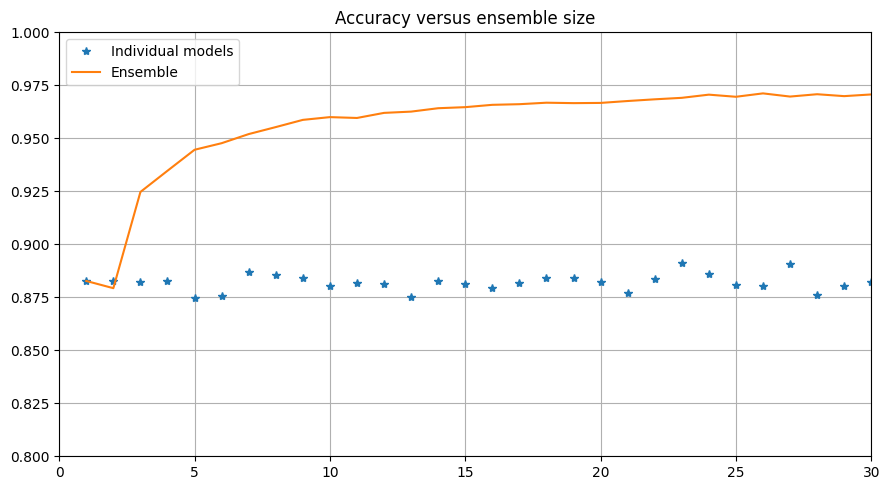

In [ ]:
fig0, ax0 = plt.subplots(figsize=(9,5))
ax0.set_title('Accuracy versus ensemble size')
plt.grid(True)
ax0.plot(np.arange(1,len(model_acc)+1), model_acc,'*',label = 'Individual models')
ax0.plot(np.arange(1,len(model_acc)+1), ens_acc,label = 'Ensemble')
ax0.legend(loc='upper left')
ax0.set_xlim(0,30)
ax0.set_ylim(0.8,1)
fig0.tight_layout()

Now let's try using the Gini criterion

Model 0 Accuracy 0.8791
Ensemble Accuracy 0.8791
Model 1 Accuracy 0.876
Ensemble Accuracy 0.875
Model 2 Accuracy 0.8758
Ensemble Accuracy 0.9141
Model 3 Accuracy 0.8751
Ensemble Accuracy 0.9341
Model 4 Accuracy 0.8729
Ensemble Accuracy 0.9422
Model 5 Accuracy 0.8798
Ensemble Accuracy 0.9477
Model 6 Accuracy 0.879
Ensemble Accuracy 0.9502
Model 7 Accuracy 0.8818
Ensemble Accuracy 0.954
Model 8 Accuracy 0.8724
Ensemble Accuracy 0.9573
Model 9 Accuracy 0.8777
Ensemble Accuracy 0.9589
Model 10 Accuracy 0.8726
Ensemble Accuracy 0.9596
Model 11 Accuracy 0.8713
Ensemble Accuracy 0.9618
Model 12 Accuracy 0.8757
Ensemble Accuracy 0.9617
Model 13 Accuracy 0.882
Ensemble Accuracy 0.9629
Model 14 Accuracy 0.8766
Ensemble Accuracy 0.9634
Model 15 Accuracy 0.8757
Ensemble Accuracy 0.9656
Model 16 Accuracy 0.8837
Ensemble Accuracy 0.9661
Model 17 Accuracy 0.8736
Ensemble Accuracy 0.9664
Model 18 Accuracy 0.8779
Ensemble Accuracy 0.9671
Model 19 Accuracy 0.875
Ensemble Accuracy 0.9669
Model 20 Accurac

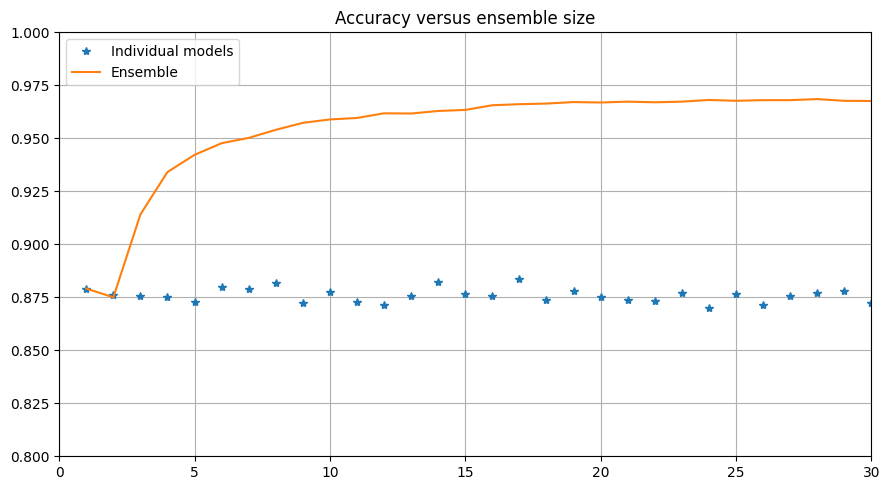

In [ ]:
model = DecisionTreeClassifier(criterion='gini', splitter='random')
preds = np.zeros((y_test.shape[0],10),dtype=int)
model_acc = []
ens_acc = []
for i in range(30):
  model = model.fit(x_train, y_train)
  pred = model.predict(x_test)
  preds[np.arange(y_test.shape[0]),pred]+=1
  accuracy = accuracy_score(y_test, pred)
  model_acc.append(accuracy)
  print(f'Model {i} Accuracy {accuracy:.4}')
  p = np.argmax(preds,axis=1)
  accuracy = accuracy_score(y_test, p)
  ens_acc.append(accuracy)
  print(f'Ensemble Accuracy {accuracy:.4}')

fig0, ax0 = plt.subplots(figsize=(9,5))
ax0.set_title('Accuracy versus ensemble size')
plt.grid(True)
ax0.plot(np.arange(1,len(model_acc)+1), model_acc,'*',label = 'Individual models')
ax0.plot(np.arange(1,len(model_acc)+1), ens_acc,label = 'Ensemble')
ax0.legend(loc='upper left')
ax0.set_xlim(0,30)
ax0.set_ylim(0.8,1)
fig0.tight_layout()

Performace using Gini is similar.

Now let's try using random feature sets.

Model 0 Accuracy 0.8796
Ensemble Accuracy 0.8796
Model 1 Accuracy 0.887
Ensemble Accuracy 0.8838
Model 2 Accuracy 0.8786
Ensemble Accuracy 0.9229
Model 3 Accuracy 0.8803
Ensemble Accuracy 0.938
Model 4 Accuracy 0.879
Ensemble Accuracy 0.9461
Model 5 Accuracy 0.8896
Ensemble Accuracy 0.9512
Model 6 Accuracy 0.8874
Ensemble Accuracy 0.9543
Model 7 Accuracy 0.8833
Ensemble Accuracy 0.9568
Model 8 Accuracy 0.8833
Ensemble Accuracy 0.9593
Model 9 Accuracy 0.8869
Ensemble Accuracy 0.9608
Model 10 Accuracy 0.8829
Ensemble Accuracy 0.9617
Model 11 Accuracy 0.8792
Ensemble Accuracy 0.9631
Model 12 Accuracy 0.8851
Ensemble Accuracy 0.9637
Model 13 Accuracy 0.8836
Ensemble Accuracy 0.9638
Model 14 Accuracy 0.8842
Ensemble Accuracy 0.9641
Model 15 Accuracy 0.8833
Ensemble Accuracy 0.9643
Model 16 Accuracy 0.8817
Ensemble Accuracy 0.9645
Model 17 Accuracy 0.8833
Ensemble Accuracy 0.9647
Model 18 Accuracy 0.885
Ensemble Accuracy 0.9655
Model 19 Accuracy 0.8777
Ensemble Accuracy 0.9657
Model 20 Accur

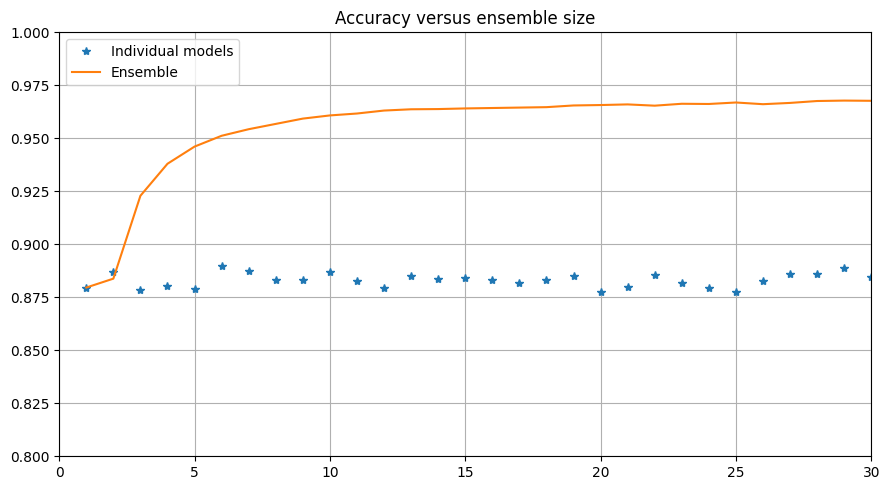

In [ ]:
model = DecisionTreeClassifier(criterion='entropy')
preds = np.zeros((y_test.shape[0],10),dtype=int)
feature_pct = 0.6
model_acc = []
ens_acc = []
for i in range(30):
  features = np.random.permutation(x_train.shape[1])[:int(x_train.shape[1]*feature_pct+0.5)]
  model = model.fit(x_train[:,features], y_train)
  pred = model.predict(x_test[:,features])
  preds[np.arange(y_test.shape[0]),pred]+=1
  accuracy = accuracy_score(y_test, pred)
  model_acc.append(accuracy)
  print(f'Model {i} Accuracy {accuracy:.4}')
  p = np.argmax(preds,axis=1)
  accuracy = accuracy_score(y_test, p)
  ens_acc.append(accuracy)
  print(f'Ensemble Accuracy {accuracy:.4}')

fig0, ax0 = plt.subplots(figsize=(9,5))
ax0.set_title('Accuracy versus ensemble size')
plt.grid(True)
ax0.plot(np.arange(1,len(model_acc)+1), model_acc,'*', label = 'Individual models')
ax0.plot(np.arange(1,len(model_acc)+1), ens_acc,label = 'Ensemble')
ax0.legend(loc='upper left')
ax0.set_xlim(0,30)
ax0.set_ylim(0.8,1)
fig0.tight_layout()

Now let's try using random examples for our training set.

Model 0 Accuracy 0.8665
Ensemble Accuracy 0.8665
Model 1 Accuracy 0.8589
Ensemble Accuracy 0.8672
Model 2 Accuracy 0.8716
Ensemble Accuracy 0.9118
Model 3 Accuracy 0.8658
Ensemble Accuracy 0.9282
Model 4 Accuracy 0.8655
Ensemble Accuracy 0.9364
Model 5 Accuracy 0.8705
Ensemble Accuracy 0.9423
Model 6 Accuracy 0.8702
Ensemble Accuracy 0.9467
Model 7 Accuracy 0.8639
Ensemble Accuracy 0.9504
Model 8 Accuracy 0.8681
Ensemble Accuracy 0.9533
Model 9 Accuracy 0.8669
Ensemble Accuracy 0.955
Model 10 Accuracy 0.8646
Ensemble Accuracy 0.9567
Model 11 Accuracy 0.8715
Ensemble Accuracy 0.9578
Model 12 Accuracy 0.867
Ensemble Accuracy 0.9587
Model 13 Accuracy 0.8646
Ensemble Accuracy 0.9597
Model 14 Accuracy 0.8658
Ensemble Accuracy 0.9588
Model 15 Accuracy 0.8647
Ensemble Accuracy 0.9599
Model 16 Accuracy 0.8683
Ensemble Accuracy 0.9609
Model 17 Accuracy 0.8652
Ensemble Accuracy 0.9608
Model 18 Accuracy 0.8686
Ensemble Accuracy 0.962
Model 19 Accuracy 0.861
Ensemble Accuracy 0.9624
Model 20 Accur

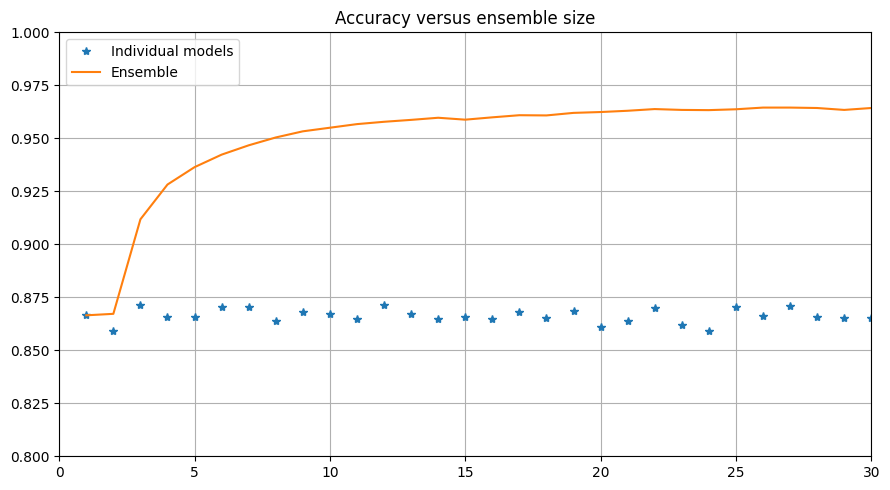

In [ ]:
model = DecisionTreeClassifier(criterion='entropy', splitter='random')
preds = np.zeros((y_test.shape[0],10),dtype=int)
model_acc = []
ens_acc = []
for i in range(30):
  samples = np.random.randint(0,x_train.shape[0],size=x_train.shape[0])
  model = model.fit(x_train[samples], y_train[samples])
  pred = model.predict(x_test)
  preds[np.arange(y_test.shape[0]),pred]+=1
  accuracy = accuracy_score(y_test, pred)
  model_acc.append(accuracy)
  print(f'Model {i} Accuracy {accuracy:.4}')
  p = np.argmax(preds,axis=1)
  accuracy = accuracy_score(y_test, p)
  ens_acc.append(accuracy)
  print(f'Ensemble Accuracy {accuracy:.4}')

fig0, ax0 = plt.subplots(figsize=(9,5))
ax0.set_title('Accuracy versus ensemble size')
plt.grid(True)
ax0.plot(np.arange(1,len(model_acc)+1), model_acc,'*',label = 'Individual models')
ax0.plot(np.arange(1,len(model_acc)+1), ens_acc,label = 'Ensemble')
ax0.legend(loc='upper left')
ax0.set_xlim(0,30)
ax0.set_ylim(0.8,1)
fig0.tight_layout()

Now we will use every tree to predict class probabilities instead of classes. This may allow us to use smaller trees in the ensemble.

Model 0 Accuracy 0.8751
Ensemble Accuracy 0.8751
Model 1 Accuracy 0.8773
Ensemble Accuracy 0.89
Model 2 Accuracy 0.8802
Ensemble Accuracy 0.9243
Model 3 Accuracy 0.8801
Ensemble Accuracy 0.9355
Model 4 Accuracy 0.8795
Ensemble Accuracy 0.9419
Model 5 Accuracy 0.8742
Ensemble Accuracy 0.9446
Model 6 Accuracy 0.8772
Ensemble Accuracy 0.9472
Model 7 Accuracy 0.8812
Ensemble Accuracy 0.9495
Model 8 Accuracy 0.8751
Ensemble Accuracy 0.9511
Model 9 Accuracy 0.8733
Ensemble Accuracy 0.9531
Model 10 Accuracy 0.8765
Ensemble Accuracy 0.9532
Model 11 Accuracy 0.8778
Ensemble Accuracy 0.9538
Model 12 Accuracy 0.8828
Ensemble Accuracy 0.9559
Model 13 Accuracy 0.8764
Ensemble Accuracy 0.9563
Model 14 Accuracy 0.8781
Ensemble Accuracy 0.9581
Model 15 Accuracy 0.8792
Ensemble Accuracy 0.9589
Model 16 Accuracy 0.8748
Ensemble Accuracy 0.9586
Model 17 Accuracy 0.8795
Ensemble Accuracy 0.9592
Model 18 Accuracy 0.8798
Ensemble Accuracy 0.9607
Model 19 Accuracy 0.8792
Ensemble Accuracy 0.9599
Model 20 Acc

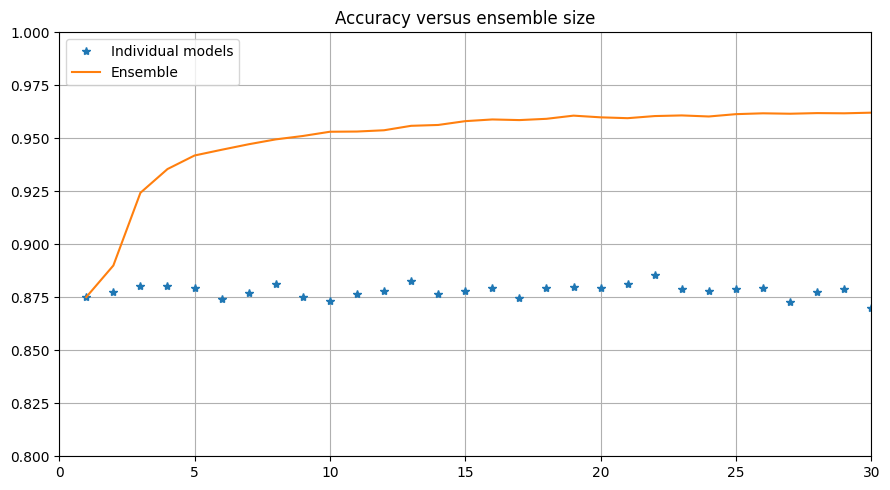

In [ ]:
model = DecisionTreeClassifier(criterion='entropy', max_depth = 12, splitter='random')
preds = np.zeros((y_test.shape[0],10),dtype=int)
model_acc = []
ens_acc = []
pred_prob_sum = 0
for i in range(30):
  model = model.fit(x_train, y_train)
  pred_prob = model.predict_proba(x_test)
  pred = np.argmax(pred_prob,axis=1)
  pred_prob_sum += pred_prob
  accuracy = accuracy_score(y_test, pred)
  model_acc.append(accuracy)
  print(f'Model {i} Accuracy {accuracy:.4}')
  p = np.argmax(pred_prob_sum,axis=1)
  accuracy = accuracy_score(y_test, p)
  ens_acc.append(accuracy)
  print(f'Ensemble Accuracy {accuracy:.4}')

fig0, ax0 = plt.subplots(figsize=(9,5))
ax0.set_title('Accuracy versus ensemble size')
plt.grid(True)
ax0.plot(np.arange(1,len(model_acc)+1), model_acc, '*', label = 'Individual models')
ax0.plot(np.arange(1,len(model_acc)+1), ens_acc,label = 'Ensemble')
ax0.legend(loc='upper left')
ax0.set_xlim(0,30)
ax0.set_ylim(0.8,1)
fig0.tight_layout()

Model 0 Accuracy 0.8821
Ensemble Accuracy 0.8821
Model 1 Accuracy 0.881
Ensemble Accuracy 0.8836
Model 2 Accuracy 0.8786
Ensemble Accuracy 0.9227
Model 3 Accuracy 0.8897
Ensemble Accuracy 0.9383
Model 4 Accuracy 0.8815
Ensemble Accuracy 0.9482
Model 5 Accuracy 0.8832
Ensemble Accuracy 0.9523
Model 6 Accuracy 0.8812
Ensemble Accuracy 0.9565
Model 7 Accuracy 0.8785
Ensemble Accuracy 0.9569
Model 8 Accuracy 0.88
Ensemble Accuracy 0.9593
Model 9 Accuracy 0.8737
Ensemble Accuracy 0.96
Model 10 Accuracy 0.8803
Ensemble Accuracy 0.9621
Model 11 Accuracy 0.8822
Ensemble Accuracy 0.9634
Model 12 Accuracy 0.8876
Ensemble Accuracy 0.9647
Model 13 Accuracy 0.8871
Ensemble Accuracy 0.9658
Model 14 Accuracy 0.8826
Ensemble Accuracy 0.9654
Model 15 Accuracy 0.8733
Ensemble Accuracy 0.9665
Model 16 Accuracy 0.8802
Ensemble Accuracy 0.9664
Model 17 Accuracy 0.8837
Ensemble Accuracy 0.9668
Model 18 Accuracy 0.8827
Ensemble Accuracy 0.9673
Model 19 Accuracy 0.8854
Ensemble Accuracy 0.968
Model 20 Accurac

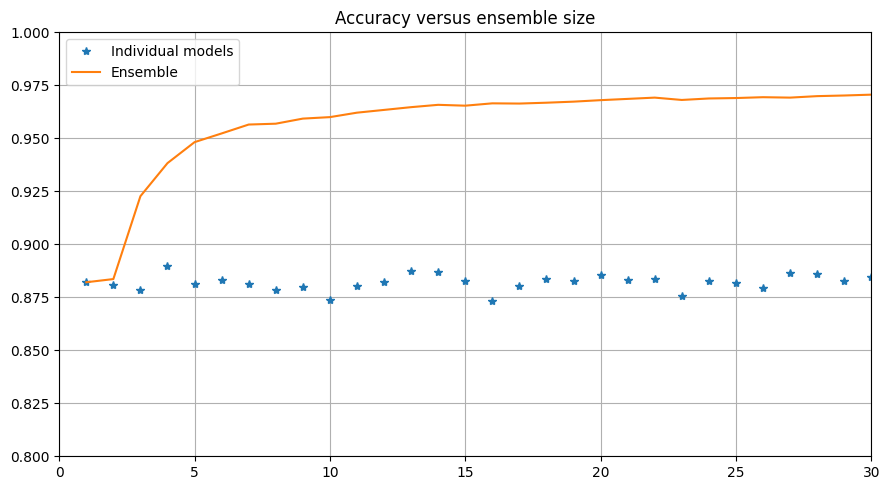

In [ ]:
model = DecisionTreeClassifier(criterion='entropy',  splitter='random')
preds = np.zeros((y_test.shape[0],10),dtype=int)
model_acc = []
ens_acc = []
pred_prob_sum = 0
for i in range(30):
  model = model.fit(x_train, y_train)
  pred_prob = model.predict_proba(x_test)
  pred = np.argmax(pred_prob,axis=1)
  pred_prob_sum += pred_prob
  accuracy = accuracy_score(y_test, pred)
  model_acc.append(accuracy)
  print(f'Model {i} Accuracy {accuracy:.4}')
  p = np.argmax(pred_prob_sum,axis=1)
  accuracy = accuracy_score(y_test, p)
  ens_acc.append(accuracy)
  print(f'Ensemble Accuracy {accuracy:.4}')

fig0, ax0 = plt.subplots(figsize=(9,5))
ax0.set_title('Accuracy versus ensemble size')
plt.grid(True)
ax0.plot(np.arange(1,len(model_acc)+1), model_acc, '*', label = 'Individual models')
ax0.plot(np.arange(1,len(model_acc)+1), ens_acc,label = 'Ensemble')
ax0.legend(loc='upper left')
ax0.set_xlim(0,30)
ax0.set_ylim(0.8,1)
fig0.tight_layout()

## **Sklearn classification ensembles**

Now let's use the sklearn classifier that performs the same operations, the random forest classifier.

See https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html

Training time: 57.6961 seconds
Prediction time: 0.4142 seconds
Accuracy 0.9692


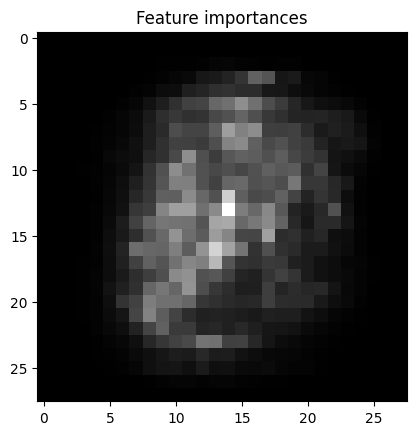

In [ ]:
start_time = time.time()
model = RandomForestClassifier()
model = model.fit(x_train, y_train)
end_time = time.time()
training_time = end_time - start_time
print(f'Training time: {training_time:.4f} seconds')

start_time = time.time()
pred = model.predict(x_test)
end_time = time.time()
prediction_time = end_time - start_time
print(f'Prediction time: {prediction_time:.4f} seconds')

accuracy = accuracy_score(y_test, pred)
print(f'Accuracy {accuracy:.4}')

plt.imshow(model.feature_importances_.reshape(28,28),cmap='gray')
plt.title("Feature importances")
plt.show()

Training time: 46.5513 seconds
Prediction time: 0.5072 seconds
Accuracy 0.9695


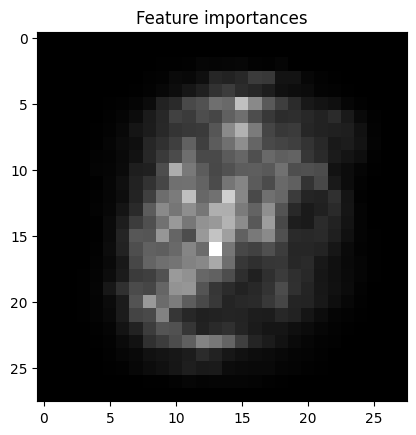

In [ ]:
start_time = time.time()
model = RandomForestClassifier(n_jobs=-1)
model = model.fit(x_train, y_train)
end_time = time.time()
training_time = end_time - start_time
print(f'Training time: {training_time:.4f} seconds')

start_time = time.time()
pred = model.predict(x_test)
end_time = time.time()
prediction_time = end_time - start_time
print(f'Prediction time: {prediction_time:.4f} seconds')

accuracy = accuracy_score(y_test, pred)
print(f'Accuracy {accuracy:.4}')

plt.imshow(model.feature_importances_.reshape(28,28),cmap='gray')
plt.title("Feature importances")
plt.show()

Training time: 15.7404 seconds
Prediction time: 0.0909 seconds
Accuracy 0.9644


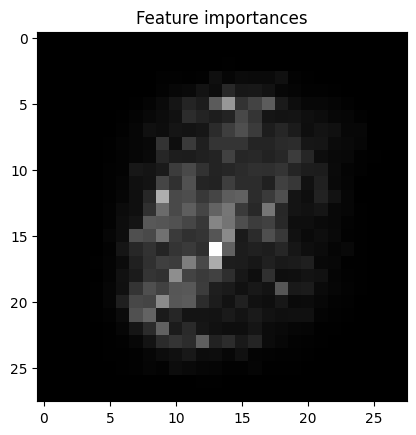

In [ ]:
start_time = time.time()
model = RandomForestClassifier(n_estimators=30, criterion='entropy',n_jobs=-1)
model = model.fit(x_train, y_train)
end_time = time.time()
training_time = end_time - start_time
print(f'Training time: {training_time:.4f} seconds')

start_time = time.time()
pred = model.predict(x_test)
end_time = time.time()
prediction_time = end_time - start_time
print(f'Prediction time: {prediction_time:.4f} seconds')

accuracy = accuracy_score(y_test, pred)
print(f'Accuracy {accuracy:.4}')

plt.imshow(model.feature_importances_.reshape(28,28),cmap='gray')
plt.title("Feature importances")
plt.show()

Training time: 51.9294 seconds
Prediction time: 0.4955 seconds
Accuracy 0.9698


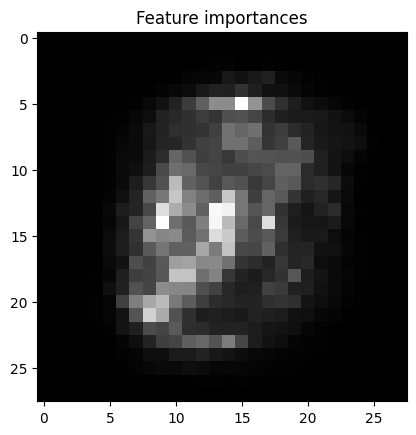

In [ ]:
start_time = time.time()
model = RandomForestClassifier(n_estimators=100, criterion='entropy',n_jobs=-1)
model = model.fit(x_train, y_train)
end_time = time.time()
training_time = end_time - start_time
print(f'Training time: {training_time:.4f} seconds')

start_time = time.time()
pred = model.predict(x_test)
end_time = time.time()
prediction_time = end_time - start_time
print(f'Prediction time: {prediction_time:.4f} seconds')

accuracy = accuracy_score(y_test, pred)
print(f'Accuracy {accuracy:.4}')

plt.imshow(model.feature_importances_.reshape(28,28),cmap='gray')
plt.title("Feature importances")
plt.show()

In [ ]:
model = ExtraTreesClassifier(n_estimators=30, criterion='entropy', n_jobs=-1)
model = model.fit(x_train, y_train)
pred = model.predict(x_test)
accuracy = accuracy_score(y_test, pred)
print(f'Accuracy {accuracy:.4}')

Accuracy 0.9674


In [ ]:
model = GradientBoostingClassifier(n_estimators=30, verbose=2)
model = model.fit(x_train, y_train)
pred = model.predict(x_test)
accuracy = accuracy_score(y_test, pred)
print(f'Accuracy {accuracy:.4}')

      Iter       Train Loss   Remaining Time 
         1           1.9103           18.75m
         2           1.6843           18.09m
         3           1.5170           17.41m
         4           1.3837           16.75m
         5           1.2679           16.11m
         6           1.1712           15.46m
         7           1.0834           14.80m
         8           1.0090           14.14m
         9           0.9433           13.49m
        10           0.8849           12.86m
        11           0.8351           12.22m
        12           0.7896           11.60m
        13           0.7467           10.96m
        14           0.7091           10.32m
        15           0.6776            9.67m
        16           0.6472            9.03m
        17           0.6217            8.38m
        18           0.5965            7.74m
        19           0.5729            7.10m
        20           0.5524            6.45m
        21           0.5327            5.81m
        2

In [ ]:
model = HistGradientBoostingClassifier(max_iter=30, verbose=1)
model = model.fit(x_train, y_train)
pred = model.predict(x_test)
accuracy = accuracy_score(y_test, pred)
print(f'Accuracy {accuracy:.4}')

Binning 0.339 GB of training data: 3.426 s
Binning 0.038 GB of validation data: 0.208 s
Fitting gradient boosted rounds:
Fit 300 trees in 164.276 s, (9300 total leaves)
Time spent computing histograms: 140.367s
Time spent finding best splits:  17.158s
Time spent applying splits:      1.123s
Time spent predicting:           0.054s
Accuracy 0.9613


In [ ]:
from xgboost import XGBClassifier

model = XGBClassifier(n_estimators=30)
model.fit(x_train, y_train, verbose=True)

In [ ]:
pred = model.predict(x_test)
accuracy = accuracy_score(y_test, pred)
print(f'Accuracy {accuracy:.4}')

In [ ]:
model = XGBClassifier(n_estimators=30, tree_method = "gpu_hist")
model.fit(x_train, y_train, verbose=True)
pred = model.predict(x_test)
accuracy = accuracy_score(y_test, pred)
print(f'Accuracy {accuracy:.4}')

In [ ]:
from sklearn.ensemble import AdaBoostClassifier

start_time = time.time()
model = AdaBoostClassifier(estimator=DecisionTreeClassifier(criterion='entropy',max_depth=20), n_estimators=10)
model.fit(x_train, y_train)
end_time = time.time()
training_time = end_time - start_time
print(f'Training time: {training_time:.4f} seconds')

start_time = time.time()
pred = model.predict(x_test)
end_time = time.time()
prediction_time = end_time - start_time
print(f'Prediction time: {prediction_time:.4f} seconds')

accuracy = accuracy_score(y_test, pred)
print(f'Accuracy {accuracy:.4}')

plt.imshow(model.feature_importances_.reshape(28,28),cmap='gray')
plt.title("Feature importances")
plt.show()



In [ ]:
trees = model.estimators_
for t in trees:
  print(f"The tree's depth is {t.get_depth()}")

# **Regression Forests**

Now we'll experiment with a regression dataset, the gpu dataset.

We will use the random forest regressor provided in sklearn. See https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeRegressor.html

In [ ]:
uploaded = files.upload()

In [ ]:
df = pd.read_csv('gpu_running_time.csv')
df

In [ ]:
for c in df.columns:
  hist = df.hist(column=c, bins=10)

We convert the dataframe to a numpy array and extract the features (X) and target (y).



In [ ]:
data = df.to_numpy()
X = data[:,:-4]
y = np.mean(data[:,-4:],axis=1)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=4361)

In [ ]:
y[0]


In [ ]:
data[0]

As a baseline, we evaluate the error when we use the mean of *y_train* as predicition for all examples in the test set.

In [ ]:
pred = np.mean(y_train)+np.zeros_like(y_test)
print('Mean squared error = {:5.2f}'.format(mean_squared_error(pred,y_test)))
print('Mean absolute error =  {:5.2f}'.format(mean_absolute_error(pred,y_test)))

Now let's evaluate a decision tree for this task.

In [ ]:
model = DecisionTreeRegressor()
model.fit(X_train,y_train)
pred = model.predict(X_test)
print('Mean squared error = {:5.2f}'.format(mean_squared_error(pred,y_test)))
print('Mean absolute error =  {:5.2f}'.format(mean_absolute_error(pred,y_test)))

In [ ]:
def predict_ensemble(X_test, model_list):
  p = 0
  for m in model_list:
    p += m.predict(X_test)
  return p/len(model_list)


# Create list of models
model_list = []
for i in range(10):
  model = DecisionTreeRegressor(splitter = 'random')
  model.fit(X_train,y_train)
  model_list.append(model)
pred = predict_ensemble(X_test, model_list)
print('The mean squared error of the ensemble is:')
print(f'{mean_squared_error(y_test,pred):6.4f}')

In [ ]:
model = DecisionTreeRegressor(splitter='random')
sum_pred = 0
model_mse, ens_mse = [], []
for i in range(100):
  model.fit(X_train,y_train)
  pred = model.predict(X_test)
  mse = mean_squared_error(pred,y_test)
  model_mse.append(mse)
  sum_pred += pred
  msee = mean_squared_error(sum_pred/(i+1),y_test)
  ens_mse.append(msee)
  print(f'Model {i:2} MSE {mse:.6} Ensemble MSE {msee:.6}')


In [ ]:
def reg(X_train,y_train,X_test):
  model = DecisionTreeRegressor(splitter='random')
  model.fit(X_train,y_train)
  pred = model.predict(X_test)
  return pred

In [ ]:
fig0, ax0 = plt.subplots(figsize=(9,5))
ax0.set_title('MSE versus ensemble size')
plt.grid(True)
ax0.plot(np.arange(1,len(model_mse)+1), model_mse,label = 'Individual models')
ax0.plot(np.arange(1,len(model_mse)+1), ens_mse,label = 'Ensemble')
ax0.legend(loc='upper left')
fig0.tight_layout()

## **Sklearn regression ensembles**

We will use the regression forest implementation described here: https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html

In [ ]:
model = RandomForestRegressor(n_jobs=-1)
model.fit(X_train,y_train)
pred_train = model.predict(X_train)
pred_test = model.predict(X_test)
print('Mean squared error training = {:7.5f}'.format(mean_squared_error(pred_train,y_train)))
print('Mean squared error test set = {:7.5f}'.format(mean_squared_error(pred_test,y_test)))

In [ ]:
model = ExtraTreesRegressor(n_jobs=-1)
model.fit(X_train,y_train)
pred_train = model.predict(X_train)
pred_test = model.predict(X_test)
print('Mean squared error training = {:7.5f}'.format(mean_squared_error(pred_train,y_train)))
print('Mean squared error test set = {:7.5f}'.format(mean_squared_error(pred_test,y_test)))

In [ ]:
model = GradientBoostingRegressor(verbose=2)
model.fit(X_train,y_train)
pred_train = model.predict(X_train)
pred_test = model.predict(X_test)
print('Mean squared error training = {:7.5f}'.format(mean_squared_error(pred_train,y_train)))
print('Mean squared error test set = {:7.5f}'.format(mean_squared_error(pred_test,y_test)))


In [ ]:
model = HistGradientBoostingRegressor(verbose=2)
model.fit(X_train,y_train)
pred_train = model.predict(X_train)
pred_test = model.predict(X_test)
print('Mean squared error training = {:7.5f}'.format(mean_squared_error(pred_train,y_train)))
print('Mean squared error test set = {:7.5f}'.format(mean_squared_error(pred_test,y_test)))